# ACA N.º 2 · Aprendizaje Automático (CUN)
## Paso 2. Preparación de los datos y pipeline para la red neuronal
**Proyecto:** Predicción de deserción estudiantil con redes neuronales
**Pilar:** Educación · **Dataset:** UCI *Predict Students Dropout and Academic Success* (Martins et al., 2021)
**Docente:** Dr. Hamilton Rivera Flor

**Integrantes:** Johan Manuel Buitrago Segura · Yadlif Mateo Hernández Zapata · Cristian David Muñoz Sánchez · Edna Catalina Osorio Alzate · Camilo José Patiño Rodríguez

---
### ¿Qué hace este notebook?
Toma los datos de la base SQLite construida en el **Paso 1** y los deja en el formato exacto que necesita una red neuronal (perceptrón multicapa, MLP):

1. Lee los datos **desde la base de datos** (`vista_modelo`).
2. Separa entradas y objetivo, y codifica las 3 clases.
3. Divide en **entrenamiento, validación y prueba** (70 / 15 / 15), de forma estratificada.
4. Crea variables nuevas (**ingeniería de características**) a partir de lo observado en el EDA.
5. Construye un **pipeline** que codifica (*one-hot*) y escala, ajustado **solo con el entrenamiento**.
6. Prepara dos estrategias contra el **desbalance**: pesos por clase y **aumento de datos sintéticos** con SMOTE-NC.
7. Guarda todo para el Paso 3 (modelado) y para la app de Streamlit.

> **Regla que guía todo el notebook:** nada de lo que se aprende de los datos (medias, desviaciones, categorías, datos sintéticos) puede salir del conjunto de **prueba** ni de **validación**. Así se evita la *fuga de datos* y la evaluación final es honesta.

## 1. Configuración

In [ ]:
%pip install -q imbalanced-learn   # SMOTE-NC (en Colab suele venir instalada)

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, json, sqlite3, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.utils.class_weight import compute_class_weight

SEMILLA = 42                # misma semilla en todo el proyecto → resultados reproducibles
USAR_2DO_SEM = True         # False = versión preventiva (solo información hasta el 1.er semestre)
AZUL, NEGRO, GRIS = "#1d4ed8", "#0b1220", "#9aa6bf"
np.random.seed(SEMILLA)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2. Lectura de los datos desde la base SQL del Paso 1
El notebook busca `desercion.db` en la carpeta actual. Si no está, intenta descargarlo de la carpeta `artefactos/` del repositorio del grupo y, como último recurso, pide subirlo.

In [ ]:
DB = "desercion.db"
URL_DB = "https://raw.githubusercontent.com/Yadkomateo/Desercion_escolar_ACA1/main/artefactos/desercion.db"

if not os.path.exists(DB):
    try:
        urllib.request.urlretrieve(URL_DB, DB)
        print("Base descargada desde GitHub.")
    except Exception:
        from google.colab import files
        print("Sube el archivo desercion.db generado en el Paso 1:")
        files.upload()

conn = sqlite3.connect(DB)
df = pd.read_sql("SELECT * FROM vista_modelo", conn)
print("Datos leídos desde vista_modelo:", df.shape)
df["target"].value_counts()

Datos leídos desde vista_modelo: (4424, 38)


target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

## 3. Variables de entrada (X) y objetivo (y)
- `estudiante_id` se conserva aparte solo para trazabilidad: **no** entra al modelo porque no contiene ningún patrón.
- El objetivo se codifica en enteros. La red tendrá **3 neuronas de salida** con activación *softmax*, una por clase.

In [ ]:
CLASES = ["Dropout", "Enrolled", "Graduate"]
NOMBRES = {"Dropout": "Abandono", "Enrolled": "Sigue matriculado", "Graduate": "Se gradúa"}
codigo_clase = {c: i for i, c in enumerate(CLASES)}

ids = df["estudiante_id"]
X = df.drop(columns=["estudiante_id", "target"])
y = df["target"].map(codigo_clase).astype("int64")

if not USAR_2DO_SEM:
    X = X.drop(columns=[c for c in X.columns if "_2nd_sem_" in c])

print("Codificación del objetivo:", codigo_clase)
print("Variables de entrada:", X.shape[1])

Codificación del objetivo: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Variables de entrada: 36


## 4. División en entrenamiento, validación y prueba (70 / 15 / 15)
| Conjunto | Uso |
|---|---|
| **Entrenamiento** | La red ajusta sus pesos. También aquí se calculan medias, desviaciones y categorías del preprocesamiento. |
| **Validación** | Vigilar el sobreajuste durante el entrenamiento (curvas de aprendizaje y *early stopping*) y comparar configuraciones. |
| **Prueba** | Evaluación final, **una sola vez**, con datos que el modelo nunca vio. |

La división es **estratificada**: cada conjunto conserva la proporción original de las tres clases.

In [ ]:
# Primero se aparta la prueba (15 %); luego, del resto, la validación (15 % del total)
X_temp, X_test, y_temp, y_test, id_temp, id_test = train_test_split(
    X, y, ids, test_size=0.15, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val, id_train, id_val = train_test_split(
    X_temp, y_temp, id_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=SEMILLA)

resumen = pd.DataFrame({
    conjunto: (pd.Series(yy).map(dict(enumerate(CLASES))).map(NOMBRES)
               .value_counts(normalize=True).mul(100).round(1))
    for conjunto, yy in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]
}).T
resumen.insert(0, "Estudiantes", [len(y_train), len(y_val), len(y_test)])
resumen

target,Estudiantes,Se gradúa,Abandono,Sigue matriculado
Entrenamiento,3096,49.9,32.1,18.0
Validación,664,50.0,32.1,17.9
Prueba,664,50.0,32.1,17.9


In [ ]:
# Comprobación: ningún estudiante aparece en dos conjuntos
assert not (set(id_train) & set(id_val) or set(id_train) & set(id_test) or set(id_val) & set(id_test))
print("✅ Los tres conjuntos son disjuntos.")

# Trazabilidad: se registra en la base de datos a qué conjunto pertenece cada estudiante
particiones = pd.concat([
    pd.DataFrame({"estudiante_id": id_train, "conjunto": "entrenamiento"}),
    pd.DataFrame({"estudiante_id": id_val,   "conjunto": "validacion"}),
    pd.DataFrame({"estudiante_id": id_test,  "conjunto": "prueba"}),
])
particiones.to_sql("particiones", conn, if_exists="replace", index=False)
pd.read_sql("SELECT conjunto, COUNT(*) AS estudiantes FROM particiones GROUP BY conjunto", conn)

✅ Los tres conjuntos son disjuntos.


,conjunto,estudiantes
0,entrenamiento,3096
1,prueba,664
2,validacion,664


**Interpretación.** Los 4.424 estudiantes quedaron divididos en 3.096 para entrenamiento, 664 para validación y 664 para prueba. Gracias a la estratificación, los tres conjuntos conservan casi exactamente la misma proporción de clases (≈ 50 % se gradúa, 32 % abandona y 18 % sigue matriculado), así que las métricas de validación y prueba serán representativas.

La asignación de cada estudiante quedó registrada en la tabla `particiones` de la base de datos. Así cualquier integrante puede consultar con SQL qué estudiantes se usaron para entrenar y cuáles para evaluar.

## 5. Ingeniería de características
El EDA del Paso 1 mostró que lo que separa a quienes abandonan **no es cuántas asignaturas inscriben, sino cuántas aprueban**, y que su desempeño **empeora** del 1.er al 2.º semestre. Se crean variables que capturan directamente esas dos ideas:

| Variable nueva | Fórmula | Qué captura |
|---|---|---|
| `tasa_aprob_1er_sem` | aprobadas ÷ inscritas (1.er sem.) | eficiencia académica en el 1.er semestre |
| `tasa_aprob_2do_sem` | aprobadas ÷ inscritas (2.º sem.) | eficiencia en el 2.º semestre |
| `cambio_aprobadas` | aprobadas 2.º − aprobadas 1.º | tendencia: mejora o deterioro |
| `cambio_promedio` | promedio 2.º − promedio 1.º | tendencia en las notas |

Es la versión tabular de la **ingeniería de secuencias** que menciona el enunciado: con solo dos semestres, la evolución se resume en tasas y diferencias.

La función se escribe en un **script auxiliar** (`preprocesamiento.py`). Así el pipeline guardado se puede cargar después en la app de Streamlit, que importa el mismo archivo.

In [ ]:
%%writefile preprocesamiento.py
"""Script auxiliar del proyecto: ingeniería de características para el modelo de deserción.
Lo usan el notebook (entrenamiento) y la app de Streamlit (predicción)."""
import numpy as np
import pandas as pd


def _tasa(aprobadas, inscritas):
    """Aprobadas / inscritas; 0 cuando no inscribió asignaturas."""
    return np.where(inscritas > 0, aprobadas / inscritas.replace(0, 1), 0.0)


def agregar_caracteristicas(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    X["tasa_aprob_1er_sem"] = _tasa(X["curricular_units_1st_sem_approved"],
                                    X["curricular_units_1st_sem_enrolled"])
    if "curricular_units_2nd_sem_approved" in X:
        X["tasa_aprob_2do_sem"] = _tasa(X["curricular_units_2nd_sem_approved"],
                                        X["curricular_units_2nd_sem_enrolled"])
        X["cambio_aprobadas"] = (X["curricular_units_2nd_sem_approved"]
                                 - X["curricular_units_1st_sem_approved"])
        X["cambio_promedio"] = (X["curricular_units_2nd_sem_grade"]
                                - X["curricular_units_1st_sem_grade"])
    return X

Writing preprocesamiento.py


In [ ]:
import importlib, preprocesamiento
importlib.reload(preprocesamiento)
from preprocesamiento import agregar_caracteristicas

ejemplo = agregar_caracteristicas(X_train)
nuevas = [c for c in ejemplo.columns if c not in X_train.columns]
(ejemplo[nuevas].join(y_train.map(dict(enumerate(CLASES))).map(NOMBRES).rename("resultado"))
 .groupby("resultado").mean().round(2))

,tasa_aprob_1er_sem,tasa_aprob_2do_sem,cambio_aprobadas,cambio_promedio
resultado,,,,
Abandono,0.38,0.30,-0.60,-1.28
Se gradúa,0.91,0.90,-0.05,0.04
Sigue matriculado,0.70,0.66,-0.26,-0.01


**Interpretación.** Las variables nuevas separan muy bien las tres clases, lo que confirma que vale la pena incluirlas:
- **Tasa de aprobación:** quienes se gradúan aprueban alrededor del 90 % de lo que inscriben; quienes abandonan, solo el 38 % en el 1.er semestre y el 30 % en el 2.º.
- **Cambio en las notas:** quienes abandonan bajan en promedio 1,3 puntos su promedio de un semestre a otro, mientras que los otros dos grupos se mantienen estables.

La red podría descubrir estas relaciones por sí sola, pero dárselas ya calculadas le facilita el aprendizaje con pocos datos (3.096 estudiantes de entrenamiento) y hace el modelo más fácil de explicar.

## 6. Tipos de variables y transformación de cada una
| Tipo | Transformación | Razón |
|---|---|---|
| **Categóricas nominales** (carrera, modalidad de ingreso, estado civil, titulación previa, nacionalidad, formación y ocupación de los padres) | *One-hot*, agrupando en «otras» las categorías con menos de 20 estudiantes en entrenamiento | Sus códigos no tienen orden: si entraran como números, la red interpretaría que el código 9500 es «mayor» que el 9119. Agrupar las categorías raras evita columnas casi vacías que solo agregan ruido. |
| **Binarias** (0/1) | Se dejan igual | Ya están en la escala adecuada. |
| **Numéricas** (edad, notas, asignaturas, indicadores económicos y variables nuevas) | Estandarización: media 0, desviación 1 | Las redes aprenden por descenso de gradiente: si una variable va de 0 a 190 y otra de 0 a 1, los pesos se actualizan de forma desigual y el entrenamiento se vuelve lento e inestable. |

In [ ]:
CATEGORICAS = ["marital_status", "application_mode", "course", "previous_qualification",
               "nationality", "mothers_qualification", "fathers_qualification",
               "mothers_occupation", "fathers_occupation"]
BINARIAS = ["daytime_evening_attendance", "displaced", "educational_special_needs", "debtor",
            "tuition_fees_up_to_date", "gender", "scholarship_holder", "international"]
NUMERICAS = [c for c in ejemplo.columns if c not in CATEGORICAS + BINARIAS]

tabla_tipos = pd.DataFrame({
    "Tipo": ["Categóricas", "Binarias", "Numéricas (incluye las 4 nuevas)"],
    "Variables": [len(CATEGORICAS), len(BINARIAS), len(NUMERICAS)],
    "Transformación": ["One-hot (categorías raras agrupadas)", "Sin cambio", "Estandarización"],
})
tabla_tipos

,Tipo,Variables,Transformación
0,Categóricas,9,One-hot (categorías raras agrupadas)
1,Binarias,8,Sin cambio
2,Numéricas (incluye las 4 nuevas),23,Estandarización


### Pipeline de preprocesamiento
Todo se encadena en un único objeto `Pipeline`. Se **ajusta solo con el entrenamiento** (`fit`) y después se **aplica** igual a validación, prueba y, más adelante, a los datos que ingrese el usuario en la app (`transform`).

In [ ]:
preprocesador = Pipeline([
    ("ingenieria", FunctionTransformer(agregar_caracteristicas)),
    ("columnas", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                              sparse_output=False), CATEGORICAS),
        ("bin", "passthrough", BINARIAS),
        ("num", StandardScaler(), NUMERICAS),
    ])),
])

preprocesador.fit(X_train)                      # ← solo entrenamiento
Xtr = preprocesador.transform(X_train).astype("float32")
Xva = preprocesador.transform(X_val).astype("float32")
Xte = preprocesador.transform(X_test).astype("float32")
nombres_finales = preprocesador.named_steps["columnas"].get_feature_names_out().tolist()

print("Entrenamiento:", Xtr.shape, "| Validación:", Xva.shape, "| Prueba:", Xte.shape)

Entrenamiento: (3096, 121) | Validación: (664, 121) | Prueba: (664, 121)


In [ ]:
# ¿Cuántas columnas genera cada grupo?
cat_enc = preprocesador.named_steps["columnas"].named_transformers_["cat"]
filas = []
for col, cats in zip(CATEGORICAS, cat_enc.categories_):
    n_raras = 0 if cat_enc.infrequent_categories_[CATEGORICAS.index(col)] is None \
        else len(cat_enc.infrequent_categories_[CATEGORICAS.index(col)])
    n_col = sum(1 for n in nombres_finales if n.startswith(f"cat__{col}_"))
    filas.append([col, len(cats), n_raras, n_col])
dim = pd.DataFrame(filas, columns=["Variable", "Códigos distintos", "Códigos raros agrupados", "Columnas one-hot"])
print(f"Dimensión: {X_train.shape[1]} variables originales + {len(nuevas)} nuevas → {Xtr.shape[1]} entradas para la red")
dim

Dimensión: 36 variables originales + 4 nuevas → 121 entradas para la red


,Variable,Códigos distintos,Códigos raros agrupados,Columnas one-hot
0,marital_status,6,3,4
1,application_mode,18,6,13
2,course,17,1,17
3,previous_qualification,17,10,8
4,nationality,18,16,3
5,mothers_qualification,27,18,10
6,fathers_qualification,29,20,10
7,mothers_occupation,31,20,12
8,fathers_occupation,42,30,13


**Interpretación.** Las 36 variables originales más las 4 nuevas se convierten en **121 entradas** para la red. Casi todo el aumento viene del *one-hot* de las variables categóricas.

Agrupar las categorías raras redujo mucho la dimensión. Por ejemplo, la ocupación del padre tiene 42 códigos distintos en entrenamiento, pero 30 tienen menos de 20 estudiantes. Sin agrupar habrían generado 42 columnas casi vacías; agrupadas, quedan 13. Lo mismo pasa con la nacionalidad: 16 de sus 18 códigos son raros, porque casi todos los estudiantes son del mismo país. Menos columnas vacías significa menos parámetros que la red debe aprender y menor riesgo de sobreajuste.

### Verificación del escalado y de la ausencia de fuga de datos
Si el escalador se ajustó solo con el entrenamiento, las variables numéricas deben tener **media 0 y desviación 1 exactas en entrenamiento**, y valores **cercanos pero no idénticos** en validación y prueba. Si también dieran exactamente 0 y 1 en prueba, sería señal de fuga.

In [ ]:
idx_num = [i for i, n in enumerate(nombres_finales) if n.startswith("num__")]
verif = pd.DataFrame({
    conjunto: [m[:, idx_num].mean().round(3), m[:, idx_num].std().round(3)]
    for conjunto, m in [("Entrenamiento", Xtr), ("Validación", Xva), ("Prueba", Xte)]
}, index=["Media promedio", "Desviación promedio"])
print("Valores nulos tras transformar:", int(np.isnan(np.vstack([Xtr, Xva, Xte])).sum()))
verif

Valores nulos tras transformar: 0


,Entrenamiento,Validación,Prueba
Media promedio,0.0,-0.02,-0.002
Desviación promedio,1.0,0.99,1.001


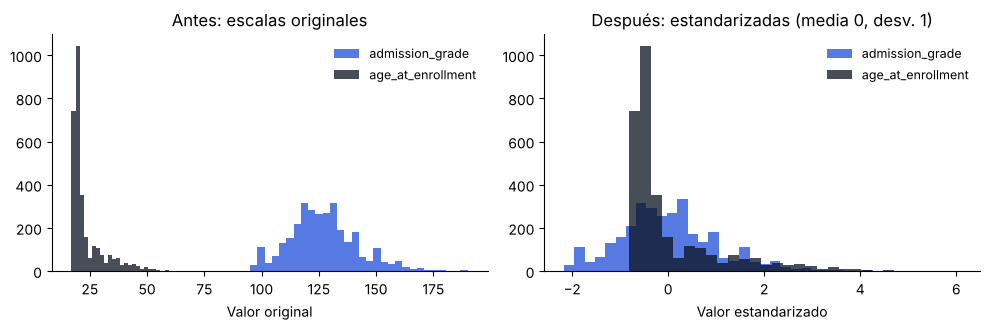

In [ ]:
# Antes y después: la estandarización pone variables de escalas muy distintas en la misma escala
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for col, color in [("admission_grade", AZUL), ("age_at_enrollment", NEGRO)]:
    axes[0].hist(X_train[col], bins=30, alpha=.75, color=color, label=col)
    axes[1].hist(Xtr[:, nombres_finales.index(f"num__{col}")], bins=30, alpha=.75, color=color, label=col)
axes[0].set_title("Antes: escalas originales"); axes[1].set_title("Después: estandarizadas (media 0, desv. 1)")
for ax in axes:
    ax.legend(frameon=False, fontsize=9); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_xlabel("Valor original"); axes[1].set_xlabel("Valor estandarizado")
plt.tight_layout(); plt.show()

**Interpretación.** La verificación confirma que **no hay fuga de datos**: las variables numéricas tienen media 0,0 y desviación 1,0 exactas en entrenamiento, y valores muy cercanos pero no idénticos en validación (−0,02 y 0,99) y prueba (−0,002 y 1,001). Además, no quedó ningún valor nulo.

El gráfico muestra el efecto del escalado: antes, la nota de admisión (entre 95 y 190) y la edad (entre 17 y 70) estaban en rangos completamente distintos; después, ambas quedan centradas en 0 y en la misma escala. La forma de cada distribución no cambia, solo su escala, así que la información se conserva.

## 7. Desbalance de clases y aumento de datos
La clase «sigue matriculado» es la más pequeña (≈ 18 %). Si no se compensa, la red aprende a ignorarla. Se preparan **dos estrategias**, y el Paso 3 elegirá la que dé mejor F1 macro en **validación**:

**A. Pesos por clase.** No cambia los datos: la función de pérdida castiga más los errores en las clases pequeñas.

**B. Aumento de datos con SMOTE-NC** (*Synthetic Minority Over-sampling Technique – Nominal Continuous*; Chawla et al., 2002). Genera estudiantes **sintéticos** de las clases minoritarias: toma un estudiante real, busca sus vecinos más parecidos de la misma clase y crea uno nuevo «entre» ellos. Es una forma de **generación de datos** basada en los patrones de los datos reales.

¿Por qué la variante **NC** y no el SMOTE clásico? El SMOTE clásico interpola números. Si se aplicara después del *one-hot*, podría crear un estudiante que es «0,4 de Enfermería y 0,6 de Turismo», algo que no existe. SMOTE-NC interpola solo las variables numéricas y, para las categóricas, asigna la categoría más frecuente entre los vecinos. Por eso se aplica sobre los datos **originales**, antes del *one-hot*.

> SMOTE-NC se aplica **solo al entrenamiento**. Validación y prueba conservan únicamente estudiantes reales, porque deben representar la realidad que el modelo enfrentará.

In [ ]:
# Estrategia A: pesos por clase (inversamente proporcionales a la frecuencia)
pesos = compute_class_weight("balanced", classes=np.arange(3), y=y_train)
PESOS_CLASE = {int(i): round(float(p), 4) for i, p in enumerate(pesos)}
pd.DataFrame({"Clase": [NOMBRES[c] for c in CLASES], "Peso en la pérdida": list(PESOS_CLASE.values())})

,Clase,Peso en la pérdida
0,Abandono,1.0372
1,Sigue matriculado,1.8561
2,Se gradúa,0.6680


In [ ]:
# Estrategia B: SMOTE-NC sobre el entrenamiento ORIGINAL (antes del one-hot)
from imblearn.over_sampling import SMOTENC

smote = SMOTENC(categorical_features=CATEGORICAS + BINARIAS, random_state=SEMILLA, k_neighbors=5)
X_train_smote, ytr_smote = smote.fit_resample(X_train, y_train.to_numpy())

# Los sintéticos pasan por el MISMO preprocesador (ajustado solo con estudiantes reales)
Xtr_smote = preprocesador.transform(X_train_smote).astype("float32")
print(f"Entrenamiento original: {len(y_train):,} estudiantes → con SMOTE-NC: {len(ytr_smote):,} "
      f"({len(ytr_smote) - len(y_train):,} sintéticos)".replace(",", "."))

# Control de calidad: los sintéticos tienen categorías válidas (no hay «medio Enfermería, medio Turismo»)
sinteticos = X_train_smote.iloc[len(X_train):]
validas = all(sinteticos[c].isin(X_train[c].unique()).all() for c in CATEGORICAS + BINARIAS)
print("¿Todas las categorías de los sintéticos son códigos reales?", "✅ Sí" if validas else "❌ No")

Entrenamiento original: 3.096 estudiantes → con SMOTE-NC: 4.635 (1.539 sintéticos)
¿Todas las categorías de los sintéticos son códigos reales? ✅ Sí


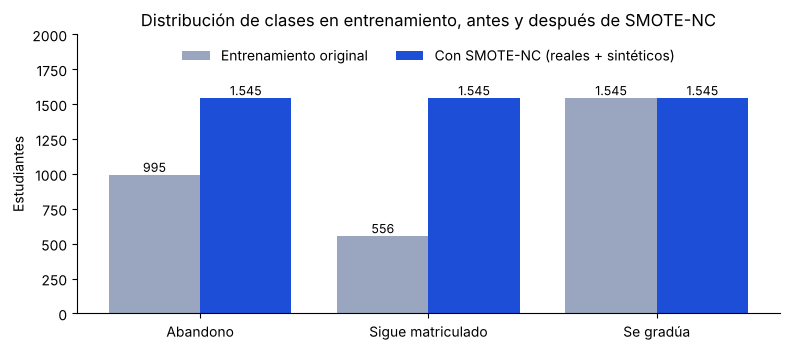

In [ ]:
antes = pd.Series(y_train).value_counts().sort_index()
despues = pd.Series(ytr_smote).value_counts().sort_index()
etiquetas = [NOMBRES[c] for c in CLASES]
x = np.arange(3)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, antes.values, 0.4, color=GRIS, label="Entrenamiento original")
ax.bar(x + 0.2, despues.values, 0.4, color=AZUL, label="Con SMOTE-NC (reales + sintéticos)")
for i in range(3):
    ax.text(i - 0.2, antes.values[i] + 20, f"{antes.values[i]:,}".replace(",", "."), ha="center", fontsize=9)
    ax.text(i + 0.2, despues.values[i] + 20, f"{despues.values[i]:,}".replace(",", "."), ha="center", fontsize=9)
ax.set_xticks(x, etiquetas); ax.set_ylabel("Estudiantes")
ax.set_title("Distribución de clases en entrenamiento, antes y después de SMOTE-NC")
ax.set_ylim(0, 2000); ax.legend(frameon=False, ncol=2, loc="upper center")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Interpretación.** Las dos estrategias atacan el mismo problema de forma distinta:
- **Pesos por clase:** un error en «sigue matriculado» pesa 1,86 veces en la pérdida, mientras que uno en «se gradúa» pesa 0,67. La red se ve obligada a prestar más atención a la clase pequeña sin agregar datos.
- **SMOTE-NC:** generó 1.539 estudiantes sintéticos hasta igualar las tres clases en 1.545 cada una. La clase «sigue matriculado» casi se triplicó (de 556 a 1.545). El control de calidad confirma que todos los sintéticos tienen códigos de carrera, nacionalidad y demás categorías que existen en los datos reales.

**Riesgo a vigilar en el Paso 3:** casi dos de cada tres estudiantes de «sigue matriculado» en el entrenamiento aumentado son sintéticos. Si la red se ajusta demasiado a ellos, puede rendir bien en entrenamiento y mal en validación. Por eso la elección entre las dos estrategias se hará con el F1 macro en **validación**, que solo contiene estudiantes reales.

## 8. Guardar todo para el Paso 3 y para la app
| Archivo | Contenido | Lo usa |
|---|---|---|
| `datos_preparados.npz` | Matrices de entrenamiento (original y con SMOTE-NC), validación y prueba | Paso 3 (modelado) |
| `preprocesador.joblib` | Pipeline ajustado (ingeniería + one-hot + escalado) | App de Streamlit |
| `preprocesamiento.py` | Script auxiliar con la ingeniería de características | App de Streamlit |
| `config_preparacion.json` | Clases, pesos, columnas, versión y semilla | Paso 3 y app |
| `desercion.db` | Ahora incluye la tabla `particiones` | Trazabilidad |

In [ ]:
os.makedirs("artefactos_paso2", exist_ok=True)

np.savez_compressed("artefactos_paso2/datos_preparados.npz",
                    X_train=Xtr, y_train=y_train.to_numpy(),
                    X_train_smote=Xtr_smote, y_train_smote=ytr_smote,
                    X_val=Xva, y_val=y_val.to_numpy(),
                    X_test=Xte, y_test=y_test.to_numpy())
joblib.dump(preprocesador, "artefactos_paso2/preprocesador.joblib")

config = {
    "clases": CLASES, "nombres_clases": NOMBRES, "codigo_clase": codigo_clase,
    "pesos_clase": PESOS_CLASE, "semilla": SEMILLA, "usar_2do_sem": USAR_2DO_SEM,
    "columnas_entrada": X.columns.tolist(), "columnas_red": nombres_finales,
    "n_entradas_red": int(Xtr.shape[1]),
    "categoricas": CATEGORICAS, "binarias": BINARIAS, "numericas": NUMERICAS,
    "tamanos": {"entrenamiento": len(y_train), "validacion": len(y_val), "prueba": len(y_test),
                "entrenamiento_smote": int(len(ytr_smote))},
    "versiones": {"scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
with open("artefactos_paso2/config_preparacion.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

import shutil
shutil.copy("preprocesamiento.py", "artefactos_paso2/preprocesamiento.py")
conn.close()
shutil.copy(DB, "artefactos_paso2/desercion.db")

for f in sorted(os.listdir("artefactos_paso2")):
    print(f"{f:<28} {os.path.getsize('artefactos_paso2/' + f) / 1024:8.1f} KB")

config_preparacion.json           7.0 KB
datos_preparados.npz            434.0 KB
desercion.db                   1008.0 KB
preprocesador.joblib             13.0 KB
preprocesamiento.py               1.1 KB


In [ ]:
# Prueba de carga: el preprocesador guardado transforma igual que el original
recargado = joblib.load("artefactos_paso2/preprocesador.joblib")
assert np.allclose(recargado.transform(X_test).astype("float32"), Xte)
print("✅ El preprocesador guardado se carga y reproduce exactamente la transformación.")

✅ El preprocesador guardado se carga y reproduce exactamente la transformación.


In [ ]:
# En Colab: descargar todos los artefactos en un .zip
shutil.make_archive("artefactos_paso2", "zip", "artefactos_paso2")
try:
    from google.colab import files
    files.download("artefactos_paso2.zip")
except ImportError:
    print("Fuera de Colab: el archivo artefactos_paso2.zip quedó en la carpeta actual.")

Fuera de Colab: el archivo artefactos_paso2.zip quedó en la carpeta actual.


## 9. Conclusiones del Paso 2
1. **Lectura desde SQL:** los datos se tomaron de `vista_modelo` en la base del Paso 1, y la partición quedó registrada en la tabla `particiones`.
2. **División honesta:** 70/15/15 estratificada y reproducible (semilla 42), con verificación de que ningún estudiante aparece en dos conjuntos.
3. **Ingeniería de características:** 4 variables nuevas (tasas de aprobación y cambios entre semestres) que separan claramente las clases.
4. **Transformación coherente con una red neuronal:** *one-hot* con agrupación de categorías raras, estandarización de variables numéricas y 121 entradas finales, todo en un único pipeline ajustado solo con el entrenamiento. Se verificó la ausencia de fuga de datos.
5. **Desbalance:** dos estrategias listas para comparar en el Paso 3: pesos por clase y aumento de datos con SMOTE-NC, aplicado solo al entrenamiento y con control de calidad de los sintéticos.
6. **Artefactos guardados:** datos preparados, preprocesador (reutilizable en la app de Streamlit), script auxiliar y configuración.

**Lo que recibe el Paso 3:** una red de tipo **MLP** con **121 neuronas de entrada** y **3 de salida** (*softmax*), entrenada con `X_train` (o `X_train_smote`) y vigilada con `X_val`.

### Referencias
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953
- Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5.
- Martins, M. V., Real, M. B., Machado, J., & Becker, A. (2021). *UCI Predict Students Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.